# Clasificación de textos en Esperanto · Vehículos

**Minería de Textos · CUNEF · 2026/2027 · Fase 3**

Eduardo Bernad Soria · Gonzalo Olivares · Pedro Riveiro

Este cuaderno clasifica párrafos en esperanto en tres categorías cercanas: **coches**, **aviones** y **trenes**. Usa:

- el **dataset** de la Fase 1 (1052 párrafos de Wikipedia en esperanto), y
- la librería **`eonlp`** de la Fase 2 (tokenizador, lematizador, etiquetador y stop-words basados en reglas, hechos desde cero), instalada con `pip` desde nuestro repositorio.

| Sección | Contenido |
|---|---|
| 0 | Configuración e instalación |
| 1 | Dataset: carga (o generación), exploración y **ruido** |
| 2 | El modelo de NLP `eonlp` en acción |
| 3 | Preprocesamiento y **vectorización** (BoW y TF-IDF por clases) |
| 4 | **Entrenamiento** y selección de modelo (validación cruzada) |
| 5 | **Evaluación**: accuracy, F1 macro y matriz de confusión |
| 6 | **Clasificación de páginas web** reales |
| 7 | Conclusiones |

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eduardobernad33/Mineria-de-textos/blob/main/notebooks/clasificacion.ipynb)

**Cómo ejecutarlo:** en Google Colab, *Entorno de ejecución → Ejecutar todo*. No necesita GPU ni interacción, y tarda menos de un minuto (más la instalación).

## 0. Configuración

Parámetros de ejecución. Todos los resultados son **reproducibles**: la semilla está fijada y la versión del repositorio (librería y dataset) se elige con `REVISION_REPO`.

In [1]:
# --- Parámetros de ejecución -------------------------------------------------
REPO = "eduardobernad33/Mineria-de-textos"
REVISION_REPO = "main"      # rama, etiqueta o commit del repositorio (fijarlo para la entrega)
GENERAR_DATASET = False     # True: vuelve a descargar Wikipedia y genera el dataset (~5 min)
SEMILLA = 42                # semilla de todas las operaciones aleatorias
TAMANO_VOCABULARIO = 1000   # nº de lemas del vocabulario (los más frecuentes del train)
PROPORCION_TEST = 0.2       # 20 % de los datos para el test

In [2]:
# Instalación de nuestra librería de NLP desde GitHub (Fase 2).
!pip install -q "git+https://github.com/{REPO}.git@{REVISION_REPO}"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import os
import random
import re
import shutil
import urllib.parse
import urllib.robotparser
import subprocess
import sys
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

import eonlp

random.seed(SEMILLA)
np.random.seed(SEMILLA)
INICIO = time.time()

CLASES = ["coches", "aviones", "trenes"]
print("eonlp", eonlp.__version__, "· repositorio", REPO, "@", REVISION_REPO)

eonlp 0.1.0 · repositorio eduardobernad33/Mineria-de-textos @ main


## 1. Dataset (Fase 1)

El dataset se genera con `scripts/build_dataset.py` de nuestro repositorio: descarga 151 artículos de Wikipedia en esperanto mediante su **API** (tema 3.6), en una **revisión fija** de cada artículo (`oldid`), limpia el HTML con BeautifulSoup (tema 3.3) y guarda un párrafo por fila con la categoría del artículo.

Como la descarga tarda unos minutos, por defecto (`GENERAR_DATASET = False`) se carga el CSV ya generado y publicado en el repositorio (**ejecución asíncrona**, apartado 4.1.4 del enunciado). Con `GENERAR_DATASET = True` se clona el repositorio y se ejecuta el script. Si algo falla, el cuaderno vuelve a la versión publicada.

In [4]:
URL_DATOS = f"https://raw.githubusercontent.com/{REPO}/{REVISION_REPO}/data"


def cargar_csv(ruta):
    return pd.read_csv(ruta, sep=";", encoding="utf-8", keep_default_na=False)


def generar_dataset():
    # Clona el repositorio y ejecuta el script de la Fase 1.
    shutil.rmtree("repo", ignore_errors=True)
    subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", REVISION_REPO,
                    f"https://github.com/{REPO}.git", "repo"], check=True)
    for fichero in ["dataset.csv", "metadata.csv"]:     # borrar los publicados: así solo se usan
        os.remove(f"repo/data/{fichero}")               # si el script los vuelve a escribir completos
    subprocess.run([sys.executable, "scripts/build_dataset.py"], cwd="repo", check=True)
    return cargar_csv("repo/data/dataset.csv"), cargar_csv("repo/data/metadata.csv")


dataset = metadata = None
if GENERAR_DATASET:
    try:
        dataset, metadata = generar_dataset()
        print("Dataset generado de nuevo desde Wikipedia.")
    except Exception as error:      # sin conexión, Wikipedia caída, generación parcial...
        print(f"No se pudo generar el dataset ({error}). Se usa la versión publicada.")

if dataset is None:
    dataset = cargar_csv(f"{URL_DATOS}/dataset.csv")
    metadata = cargar_csv(f"{URL_DATOS}/metadata.csv")
    print("Dataset cargado desde el repositorio.")

# Contrato de datos: columnas text;class y sin ';' dentro del texto.
assert list(dataset.columns) == ["text", "class"]
assert not dataset["text"].str.contains(";").any()
assert (dataset["text"] == metadata["text"]).all()
print(f"{len(dataset)} párrafos · {metadata['articulo'].nunique()} artículos")
dataset.head()

Dataset cargado desde el repositorio.
1052 párrafos · 151 artículos


,text,class
0,Aŭtomobilo (el la greka autos [mem] kaj latina...,coches
1,Aŭto estas radohava motorveturilo uzata por tr...,coches
2,Aŭtoj venis al ĝenerala uzado laŭlonge de la 2...,coches
3,"Aŭtoj havas kontrolilojn por direktigo, haltig...",coches
4,La unuaj modernaj aŭtoj kun la konata stirrado...,coches


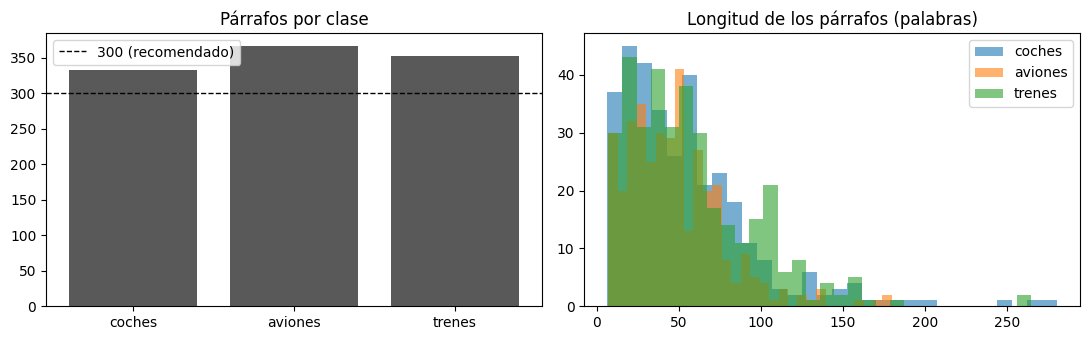

class
coches     333
aviones    367
trenes     352
Longitud media: 53 palabras (mediana 46)


In [5]:
conteo = dataset["class"].value_counts().reindex(CLASES)
palabras = dataset["text"].str.split().str.len()

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
ejes[0].bar(conteo.index, conteo.values, color="0.35")
ejes[0].axhline(300, color="black", linestyle="--", linewidth=1, label="300 (recomendado)")
ejes[0].set_title("Párrafos por clase")
ejes[0].legend()
for clase in CLASES:
    ejes[1].hist(palabras[dataset["class"] == clase], bins=30, alpha=0.6, label=clase)
ejes[1].set_title("Longitud de los párrafos (palabras)")
ejes[1].legend()
plt.tight_layout()
plt.show()

print(conteo.to_string())
print(f"Longitud media: {palabras.mean():.0f} palabras (mediana {palabras.median():.0f})")

### 1.1 Ruido del etiquetado

Cada párrafo **hereda la etiqueta de su artículo**. Eso introduce ruido: un artículo sobre un tren puede tener párrafos genéricos ("La kompanio estis fondita en 1950") que no dicen nada sobre trenes. Lo medimos de tres formas complementarias:

1. **Raíces de la clase**: porcentaje de párrafos sin ninguna raíz típica de su categoría (`aŭt`, `aviad`, `trajn`…), buscada también dentro de palabras compuestas (`pasaĝeraviadilo`, `vaporlokomotivo`). Es una cota alta: un párrafo puede hablar de su tema sin usar esas palabras (p. ej., citando solo un modelo concreto).
2. **Restos de la limpieza**: párrafos con huecos como `(.)`, que quedan al quitar enlaces o fechas.
3. **Desacuerdo con el modelo** (sección 5.3): párrafos que un modelo entrenado sin ver su artículo asigna a otra clase.

In [6]:
nlp = eonlp.load()
docs = [nlp(texto) for texto in dataset["text"]]   # análisis con eonlp (se reutiliza después)

LEMAS_DE_CLASE = {
    "coches":  ("aŭt", "ŝofor", "stir", "karoseri", "kamion", "buso"),
    "aviones": ("aviad", "aeroplan", "flug", "pilot", "alteriĝ", "aerarme", "helikopter", "jet"),
    "trenes":  ("trajn", "lokomotiv", "fervoj", "vagon", "relo", "stacidom", "metroo", "tram"),
}


def tiene_lema_de_su_clase(doc, clase):
    return any(raiz in token.lemma_.lower() for token in doc for raiz in LEMAS_DE_CLASE[clase])


sin_lema = [not tiene_lema_de_su_clase(doc, clase) for doc, clase in zip(docs, dataset["class"])]
restos = dataset["text"].str.contains(r"\(\s*[.,;]?\s*\)|\s\.\s\.|\.\.\s", regex=True)

ruido = pd.DataFrame({"class": dataset["class"], "sin_lema_de_clase": sin_lema, "restos": restos})
tabla_ruido = ruido.groupby("class")[["sin_lema_de_clase", "restos"]].mean().mul(100).round(1)
tabla_ruido.loc["total"] = ruido[["sin_lema_de_clase", "restos"]].mean().mul(100).round(1)
print("Porcentaje de párrafos (%):")
print(tabla_ruido.reindex(CLASES + ["total"]).to_string())

print("\nEjemplos de párrafos sin ningún lema de su clase:")
for clase in CLASES:
    ejemplo = dataset[(ruido["class"] == clase) & ruido["sin_lema_de_clase"]].sample(1, random_state=SEMILLA)
    print(f"  [{clase}] {ejemplo['text'].iloc[0][:140]}…")

Porcentaje de párrafos (%):
         sin_lema_de_clase  restos
class                             
coches                35.4     0.3
aviones                7.4     0.3
trenes                 8.0     0.6
total                 16.4     0.4

Ejemplos de párrafos sin ningún lema de su clase:
  [coches] LADA Vesta havas tri ĉefajn versiojn: Classic (la baza), Comfort (la meza) kaj Luxe (la pinta). Por limuzino haveblas ankaŭ la simpligita ve…
  [aviones] Produktado de A300 estis haltigita en 2007, kune kun malgrandigita modelo, A310. Nuntempe usona loĝistika kompanio FedEx Express operacias 6…
  [trenes] Malsimila al la cetero de la hispana 1672 mm reto, la AVE uzas la normalan ŝpuron de 1435 mm.…


## 2. El modelo de NLP `eonlp` (Fase 2)

`eonlp` reproduce la API de spaCy vista en clase (tema 2.2): `nlp = eonlp.load()`, `doc = nlp(texto)`, y para cada token `text`, `lemma_`, `pos_` e `is_stop`, más `doc.sents` para las frases. Todo es **basado en reglas** a partir de la gramática del esperanto, que no tiene excepciones:

- **Tokenizador**: normalización Unicode, lexicón de abreviaturas (*longest-match*) y expresiones regulares.
- **Etiquetador**: palabras gramaticales del léxico de la guía y, para el resto, la **terminación** (`-o` sustantivo, `-a` adjetivo, `-e` adverbio, `-as/-is/-os…` verbo).
- **Lematizador**: forma de diccionario (`librojn → libro`, `veturis → veturi`).
- **Stop-words**: el léxico de la guía más las formas generadas (pronombres, verbos, correlativos, ordinales).

Detalles y tests en el repositorio (`docs/` y `tests/`).

In [7]:
ejemplo = nlp("La rapidaj trajnoj veturis al Madrido. Ĉiuj aviadiloj de Boeing flugas tre alte!")
pd.DataFrame(
    [(t.text, t.lemma_, t.pos_, t.is_stop, t.is_punct) for t in ejemplo],
    columns=["text", "lemma_", "pos_", "is_stop", "is_punct"],
)

,text,lemma_,pos_,is_stop,is_punct
0,La,la,DET,True,False
1,rapidaj,rapida,ADJ,False,False
2,trajnoj,trajno,NOUN,False,False
3,veturis,veturi,VERB,False,False
4,al,al,ADP,True,False
5,Madrido,Madrido,PROPN,False,False
6,.,.,PUNCT,False,True
7,Ĉiuj,ĉiu,PRON,True,False
8,aviadiloj,aviadilo,NOUN,False,False
9,de,de,ADP,True,False


In [8]:
print("Frases:", [frase.text for frase in ejemplo.sents])

tokens_dataset = [token for doc in docs for token in doc]
palabras_dataset = [t for t in tokens_dataset if not t.is_punct]
print(f"Tokens en el dataset: {len(tokens_dataset)}")
print(f"Stop-words: {100 * sum(t.is_stop for t in palabras_dataset) / len(palabras_dataset):.1f} % de las palabras")
formas = {t.text.lower() for t in palabras_dataset}
lemas = {t.lemma_.lower() for t in palabras_dataset}
print(f"Vocabulario: {len(formas)} formas distintas -> {len(lemas)} lemas ({100 * (1 - len(lemas) / len(formas)):.0f} % menos)")

Frases: ['La rapidaj trajnoj veturis al Madrido.', 'Ĉiuj aviadiloj de Boeing flugas tre alte!']
Tokens en el dataset: 64718
Stop-words: 40.1 % de las palabras
Vocabulario: 11622 formas distintas -> 9265 lemas (20 % menos)


## 3. Preprocesamiento y vectorización

Seguimos los cinco pasos del tema 2.3 para pasar un texto a un vector:

1. **Tokenizar** (`eonlp`).
2. **Filtrar** stop-words, signos de puntuación y números.
3. **Normalizar**: minúsculas y **lema** (así `trajno`, `trajnoj` y `trajnojn` cuentan como la misma palabra).
4. **Representar** cada palabra con *one-hot* sobre un **vocabulario**: los `TAMANO_VOCABULARIO` lemas más frecuentes del **conjunto de entrenamiento**.
5. **Vectorizar el texto** con la media de sus vectores one-hot, es decir, la **frecuencia relativa** de cada palabra del vocabulario (normaliza por longitud: el vector suma 1).

Comparamos las dos representaciones del tema 2.4:

- **BoW normalizada**: el paso 5 tal cual (*TF*).
- **TF-IDF por clases**, la versión de la asignatura: `IDF(t) = 1 − log_|C|(máx(1, nº de clases que contienen t))`. Con 3 clases, una palabra que solo aparece en una clase pesa 1; en dos, 0,37; en las tres, 0. El IDF se calcula **solo con el entrenamiento**, para no usar información del test.

In [9]:
CATEGORIAS_EXCLUIDAS = {"PUNCT", "NUM", "X"}


def preprocesar(doc):
    # Pasos 1-3: lemas en minúsculas de las palabras con contenido.
    return [
        token.lemma_.lower()
        for token in doc
        if not token.is_stop and not token.is_punct and token.pos_ not in CATEGORIAS_EXCLUIDAS
    ]


lemas_por_parrafo = [preprocesar(doc) for doc in docs]
y = dataset["class"].to_numpy()

print(dataset["text"].iloc[0][:120], "…")
print("->", lemas_por_parrafo[0][:15])

Aŭtomobilo (el la greka autos [mem] kaj latina mobilis [mobila]) aŭ (kiel kutima mallongigita formo) aŭto estas, krom bi …
-> ['aŭtomobilo', 'greka', 'auti', 'latina', 'mobili', 'mobila', 'kutima', 'mallongigita', 'formo', 'aŭto', 'biciklo', 'ofte', 'uzata', 'veturilo', 'persona']


In [10]:
def crear_vocabulario(lista_lemas, tamano):
    # Paso 4: los lemas más frecuentes (solo del entrenamiento).
    frecuencias = Counter(lema for lemas in lista_lemas for lema in lemas)
    return [lema for lema, _ in frecuencias.most_common(tamano)]


def vectorizar_bow(lista_lemas, vocabulario):
    # Paso 5: frecuencia relativa de cada palabra del vocabulario (media de los one-hot).
    posicion = {lema: i for i, lema in enumerate(vocabulario)}
    X = np.zeros((len(lista_lemas), len(vocabulario)))
    for fila, lemas in enumerate(lista_lemas):
        for lema in lemas:
            if lema in posicion:
                X[fila, posicion[lema]] += 1
        total = X[fila].sum()
        if total > 0:
            X[fila] /= total
    return X


def calcular_idf_por_clases(lista_lemas, clases, vocabulario):
    # IDF de la asignatura: 1 - log_|C|(nº de clases en las que aparece la palabra).
    aparece_en = {clase: set() for clase in CLASES}
    for lemas, clase in zip(lista_lemas, clases):
        aparece_en[clase].update(lemas)
    n_clases = np.array([max(1, sum(lema in aparece_en[c] for c in CLASES)) for lema in vocabulario])
    return 1 - np.log(n_clases) / np.log(len(CLASES))


def vectorizar_tfidf(lista_lemas, vocabulario, idf):
    X = vectorizar_bow(lista_lemas, vocabulario) * idf
    totales = X.sum(axis=1, keepdims=True)
    totales[totales == 0] = 1          # textos sin palabras con peso: se quedan en ceros
    return X / totales


class Vectorizador:
    # Aprende el vocabulario (y el IDF) con el entrenamiento y transforma cualquier texto.

    def __init__(self, metodo="bow", tamano=TAMANO_VOCABULARIO):
        self.metodo = metodo
        self.tamano = tamano

    def fit(self, lista_lemas, clases):
        self.vocabulario = crear_vocabulario(lista_lemas, self.tamano)
        self.idf = calcular_idf_por_clases(lista_lemas, clases, self.vocabulario)
        return self

    def transform(self, lista_lemas):
        if self.metodo == "bow":
            return vectorizar_bow(lista_lemas, self.vocabulario)
        return vectorizar_tfidf(lista_lemas, self.vocabulario, self.idf)

In [11]:
# Partición train/test estratificada (misma proporción de clases en ambos), como en el tema 0.4.
indices = np.arange(len(dataset))
i_train, i_test = train_test_split(
    indices, test_size=PROPORCION_TEST, random_state=SEMILLA, stratify=y
)
lemas_train = [lemas_por_parrafo[i] for i in i_train]
lemas_test = [lemas_por_parrafo[i] for i in i_test]
print(f"Entrenamiento: {len(i_train)} párrafos · Test: {len(i_test)} párrafos")

vectorizador = Vectorizador("bow").fit(lemas_train, y[i_train])
X_train = vectorizador.transform(lemas_train)
print(f"Matriz de entrenamiento: {X_train.shape[0]} filas x {X_train.shape[1]} columnas")

idf = pd.Series(vectorizador.idf, index=vectorizador.vocabulario)
print("\nIDF por clases del vocabulario:")
print(idf.round(2).value_counts().sort_index().rename("nº de lemas").to_string())
print("\nEjemplos con IDF = 1 (una sola clase):", list(idf[idf == 1].index[:12]))
print("Ejemplos con IDF = 0 (las tres clases):", list(idf[idf == 0].index[:12]))

Entrenamiento: 841 párrafos · Test: 211 párrafos
Matriz de entrenamiento: 841 filas x 1000 columnas

IDF por clases del vocabulario:
0.00    431
0.37    284
1.00    285

Ejemplos con IDF = 1 (una sola clase): ['boeing', 'fervojo', 'pasaĝeraviadilo', 'airbus', 'ĉasaviadilo', 'lada', 'aerarmeo', 'flugo', 'douglas', 'dsb', 'vaporlokomotivo', 'fervoja']
Ejemplos con IDF = 0 (las tres clases): ['aviadilo', 'jaro', 'nova', 'motoro', 'modelo', 'km', 'alia', 'elektra', 'granda', 'uzi', 'poste', 'versio']


## 4. Entrenamiento y selección de modelo

Probamos los clasificadores del tema 0.4 con las dos vectorizaciones, mediante **validación cruzada de 5 particiones** (`KFold`) **sobre el conjunto de entrenamiento**. En cada partición el vocabulario y el IDF se recalculan solo con su parte de entrenamiento. El test no se toca hasta la sección 5.

In [12]:
MODELOS = {
    "Regresión logística": lambda: LogisticRegression(max_iter=1000, random_state=SEMILLA),
    "Naive Bayes":         lambda: GaussianNB(),
    "KNN (k=5)":           lambda: KNeighborsClassifier(n_neighbors=5),
    "Árbol de decisión":   lambda: DecisionTreeClassifier(random_state=SEMILLA),
}


def validacion_cruzada(metodo, crear_modelo, indices_train, n_particiones=5):
    resultados = []
    kfold = KFold(n_splits=n_particiones, shuffle=True, random_state=SEMILLA)
    for parte_train, parte_val in kfold.split(indices_train):
        i_tr, i_va = indices_train[parte_train], indices_train[parte_val]
        vect = Vectorizador(metodo).fit([lemas_por_parrafo[i] for i in i_tr], y[i_tr])
        modelo = crear_modelo().fit(vect.transform([lemas_por_parrafo[i] for i in i_tr]), y[i_tr])
        prediccion = modelo.predict(vect.transform([lemas_por_parrafo[i] for i in i_va]))
        resultados.append((accuracy_score(y[i_va], prediccion), f1_score(y[i_va], prediccion, average="macro")))
    return np.mean(resultados, axis=0)


filas = []
for metodo in ["bow", "tfidf"]:
    for nombre, crear_modelo in MODELOS.items():
        accuracy, f1 = validacion_cruzada(metodo, crear_modelo, i_train)
        filas.append({"vectorización": metodo.upper(), "modelo": nombre, "accuracy": accuracy, "F1 macro": f1})

comparacion = pd.DataFrame(filas).sort_values("F1 macro", ascending=False).reset_index(drop=True)
comparacion.style.format({"accuracy": "{:.3f}", "F1 macro": "{:.3f}"}).hide(axis="index")

vectorización,modelo,accuracy,F1 macro
TFIDF,Regresión logística,0.956,0.956
BOW,Regresión logística,0.937,0.936
TFIDF,Naive Bayes,0.920,0.918
BOW,Naive Bayes,0.912,0.911
BOW,Árbol de decisión,0.874,0.875
TFIDF,Árbol de decisión,0.866,0.868
BOW,KNN (k=5),0.837,0.840
TFIDF,KNN (k=5),0.831,0.830


In [13]:
mejor = comparacion.iloc[0]
METODO = mejor["vectorización"].lower()
NOMBRE_MODELO = mejor["modelo"]
print(f"Elegido por F1 macro en validación cruzada: {NOMBRE_MODELO} + {METODO.upper()} ({mejor['F1 macro']:.3f})")

# Entrenamiento final con todo el conjunto de entrenamiento.
vectorizador = Vectorizador(METODO).fit(lemas_train, y[i_train])
X_train = vectorizador.transform(lemas_train)
X_test = vectorizador.transform(lemas_test)
modelo = MODELOS[NOMBRE_MODELO]().fit(X_train, y[i_train])

Elegido por F1 macro en validación cruzada: Regresión logística + TFIDF (0.956)


## 5. Evaluación

### 5.1 Conjunto de test (partición aleatoria estratificada)

Métricas pedidas: **accuracy** (aciertos totales), **F1 macro** (media de F1 de las tres clases, sin que pese más la clase más grande) y **matriz de confusión**.

Accuracy: 0.929 · F1 macro: 0.929

              precision    recall  f1-score   support

      coches      0.877     0.955     0.914        67
     aviones      0.958     0.932     0.945        74
      trenes      0.955     0.900     0.926        70

    accuracy                          0.929       211
   macro avg      0.930     0.929     0.929       211
weighted avg      0.931     0.929     0.929       211



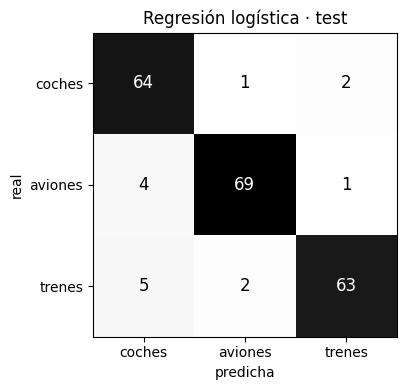

In [14]:
def dibujar_matriz(reales, predichas, titulo, eje):
    matriz = confusion_matrix(reales, predichas, labels=CLASES)
    eje.imshow(matriz, cmap="Greys")
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            color = "white" if matriz[i, j] > matriz.max() / 2 else "black"
            eje.text(j, i, matriz[i, j], ha="center", va="center", color=color, fontsize=12)
    eje.set_xticks(range(len(CLASES)), CLASES)
    eje.set_yticks(range(len(CLASES)), CLASES)
    eje.set_xlabel("predicha")
    eje.set_ylabel("real")
    eje.set_title(titulo)


prediccion_test = modelo.predict(X_test)
accuracy_test = accuracy_score(y[i_test], prediccion_test)
f1_test = f1_score(y[i_test], prediccion_test, average="macro")
print(f"Accuracy: {accuracy_test:.3f} · F1 macro: {f1_test:.3f}\n")
print(classification_report(y[i_test], prediccion_test, labels=CLASES, digits=3))

fig, eje = plt.subplots(figsize=(4.5, 4))
dibujar_matriz(y[i_test], prediccion_test, f"{NOMBRE_MODELO} · test", eje)
plt.tight_layout()
plt.show()

### 5.2 Prueba más exigente: partición por artículo

En la partición aleatoria, párrafos del **mismo artículo** caen a la vez en train y en test: el modelo puede acertar porque "reconoce el artículo" (sus nombres propios, su estilo) y no porque entienda el tema. Para medirlo, repetimos la evaluación apartando para el test **artículos completos** (el 20 % de los artículos de cada clase), usando `metadata.csv`. Así el test simula textos nuevos, como las páginas web de la sección 6.

partición,párrafos de test,accuracy,F1 macro
aleatoria (5.1),211,0.929,0.929
por artículo (5.2),216,0.852,0.852


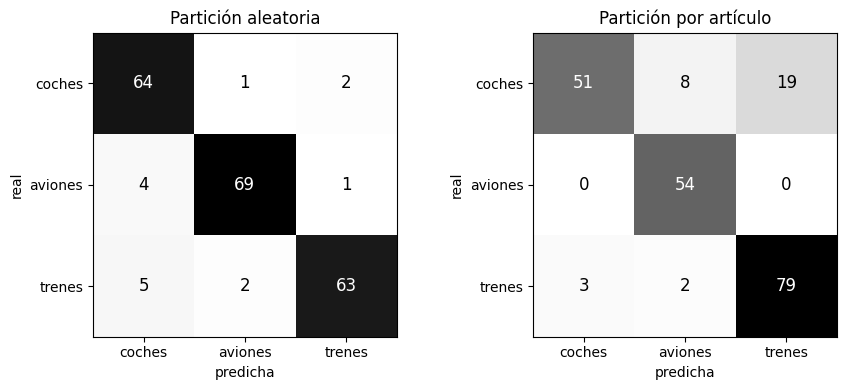

In [15]:
def particion_por_articulo(proporcion=PROPORCION_TEST, semilla=SEMILLA):
    generador = random.Random(semilla)
    articulos_test = set()
    for clase in CLASES:
        articulos = sorted(metadata.loc[metadata["class"] == clase, "articulo"].unique())
        articulos_test.update(generador.sample(articulos, round(proporcion * len(articulos))))
    en_test = metadata["articulo"].isin(articulos_test).to_numpy()
    return indices[~en_test], indices[en_test]


a_train, a_test = particion_por_articulo()
vect_art = Vectorizador(METODO).fit([lemas_por_parrafo[i] for i in a_train], y[a_train])
modelo_art = MODELOS[NOMBRE_MODELO]().fit(vect_art.transform([lemas_por_parrafo[i] for i in a_train]), y[a_train])
prediccion_art = modelo_art.predict(vect_art.transform([lemas_por_parrafo[i] for i in a_test]))

resumen = pd.DataFrame({
    "partición": ["aleatoria (5.1)", "por artículo (5.2)"],
    "párrafos de test": [len(i_test), len(a_test)],
    "accuracy": [accuracy_test, accuracy_score(y[a_test], prediccion_art)],
    "F1 macro": [f1_test, f1_score(y[a_test], prediccion_art, average="macro")],
})
display(resumen.style.format({"accuracy": "{:.3f}", "F1 macro": "{:.3f}"}).hide(axis="index"))

fig, ejes = plt.subplots(1, 2, figsize=(9, 4))
dibujar_matriz(y[i_test], prediccion_test, "Partición aleatoria", ejes[0])
dibujar_matriz(y[a_test], prediccion_art, "Partición por artículo", ejes[1])
plt.tight_layout()
plt.show()

### 5.3 Qué ha aprendido el modelo y dónde falla

Si el modelo es una regresión logística, sus coeficientes indican qué lemas empujan hacia cada clase. Después, para medir el **ruido del etiquetado** (sección 1.1), clasificamos cada párrafo con un modelo que **no ha visto su artículo** (5 particiones por artículo) y contamos cuántos se asignan a otra clase.

In [16]:
if hasattr(modelo, "coef_"):
    vocabulario = np.array(vectorizador.vocabulario)
    importantes = {clase: list(vocabulario[np.argsort(modelo.coef_[k])[::-1][:12]])
                   for k, clase in enumerate(modelo.classes_)}
    print("Lemas con más peso para cada clase:")
    for clase in CLASES:
        print(f"  {clase:8} {', '.join(importantes[clase])}")

Lemas con más peso para cada clase:
  coches   aŭto, aŭtomobilo, lada, model, benz, taksio, trabant, porsche, avtovaz, prius, ford, nymph
  aviones  boeing, ĉasaviadilo, pasaĝeraviadilo, airbus, flugo, aerarmeo, aeroplano, konkordo, piloto, flugilo, jetmotoro, flugi
  trenes   trajno, fervojo, lokomotivo, dsb, vaporlokomotivo, vagono, vagonaro, motortrajno, fervoja, metroo, regiojet, z


In [17]:
# Predicción "fuera de artículo" para todo el dataset: 5 grupos de artículos.
articulos = sorted(metadata["articulo"].unique())
random.Random(SEMILLA).shuffle(articulos)
grupo_de = {articulo: k % 5 for k, articulo in enumerate(articulos)}
grupos = metadata["articulo"].map(grupo_de).to_numpy()

prediccion_oof = np.empty(len(dataset), dtype=object)
confianza_oof = np.zeros(len(dataset))
for grupo in range(5):
    tr, va = indices[grupos != grupo], indices[grupos == grupo]
    vect = Vectorizador(METODO).fit([lemas_por_parrafo[i] for i in tr], y[tr])
    m = MODELOS[NOMBRE_MODELO]().fit(vect.transform([lemas_por_parrafo[i] for i in tr]), y[tr])
    X_va = vect.transform([lemas_por_parrafo[i] for i in va])
    prediccion_oof[va] = m.predict(X_va)
    confianza_oof[va] = m.predict_proba(X_va).max(axis=1)

discrepa = prediccion_oof != y
print("Párrafos que un modelo sin ver su artículo asigna a OTRA clase (%):")
print((pd.Series(discrepa, index=y).groupby(level=0).mean().reindex(CLASES) * 100).round(1).to_string())
print(f"  total    {100 * discrepa.mean():.1f}")

print("\nEjemplos (con la confianza del modelo):")
errores = pd.DataFrame({"text": dataset["text"], "real": y, "predicha": prediccion_oof, "confianza": confianza_oof})[discrepa]
for _, fila in errores.sample(min(6, len(errores)), random_state=SEMILLA).iterrows():
    print(f"  real={fila['real']:8} predicha={fila['predicha']:8} ({fila['confianza']:.2f}) · {fila['text'][:110]}…")

Párrafos que un modelo sin ver su artículo asigna a OTRA clase (%):
coches     14.1
aviones     9.8
trenes     16.2
  total    13.3

Ejemplos (con la confianza del modelo):
  real=trenes   predicha=aviones  (0.36) · Estanta socia simbolo en Sovetio kaj Rusio, trajnoj ER2 kaj ER9 estas la temo de kelkaj pecoj de arto kaj lite…
  real=aviones  predicha=coches   (0.35) · An–225 estis evoluigita por servo de la sovetia kosma programo, ties tasko estis transporto de la kosmoŝipo Bu…
  real=coches   predicha=trenes   (0.37) · La Model 3 estis oficiale anoncita la 31an de marto 2016. La ĉefaj karakterizaĵoj tiam estis rivelitaj, inter …
  real=trenes   predicha=coches   (0.43) · Konstruitaj fare de établissements Soulé de Bagnères-de-Bigorre, ilia korpo estas el vernisita lignaĵo (panelo…
  real=coches   predicha=aviones  (0.36) · La Dilambda estis uzata de multaj eminentuloj de la 1930-aj jaroj. Inter aliaj de la germana boksisto kaj mond…
  real=coches   predicha=aviones  (0.36) · En oktobr

**Lectura de los resultados.** Parte de estos "errores" no son fallos del modelo, sino **ruido del dataset**: párrafos genéricos (historia de una empresa, fechas, cifras) que no hablan de su vehículo, o párrafos que hablan de otra categoría (un artículo de trenes que compara con el avión). Este porcentaje es, por tanto, una estimación del ruido de etiquetado junto con el error real del modelo.

## 6. Clasificación de páginas web

Probamos el modelo con páginas reales en esperanto **que no están en el dataset**, una de cada categoría. Para cada página:

1. Se comprueba en el **`robots.txt`** del sitio que la página se puede rastrear y se descarga con `requests`, identificándonos con un **User-Agent** (tema 3.2) y con una sola petición por página y una pausa entre páginas, para no cargar el servidor (ética del *scraping*, tema 3.4).
2. Se extraen los párrafos `<p>` con BeautifulSoup (tema 3.3) y se limpian referencias y espacios.
3. Se clasifica cada párrafo con `predict_proba` y se calcula la **probabilidad de cada categoría** para la página: la media de sus párrafos ponderada por su longitud.

Si una página falla (sin conexión, error 4xx/5xx o sin texto), se avisa y se continúa con la siguiente.

OK · Aŭtomobilo-revokoj de Toyota 2009-2010 · 16 párrafos
OK · Flughaveno Frankfurto · 4 párrafos
OK · Majaa Trajno · 1 párrafos


,coches,aviones,trenes
Aŭtomobilo-revokoj de Toyota 2009-2 (esperada: coches),59.4%,21.7%,18.9%
Flughaveno Frankfurto (esperada: aviones),21.0%,48.5%,30.5%
Majaa Trajno (esperada: trenes),8.1%,8.5%,83.4%


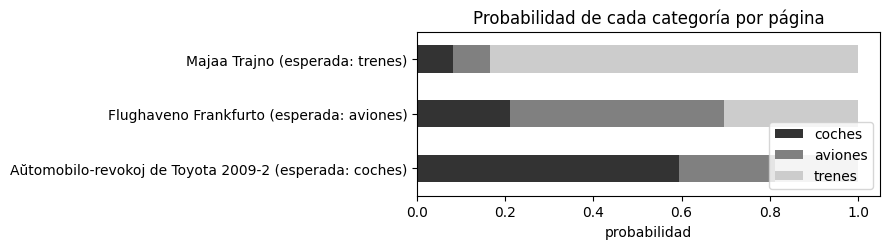

In [18]:
PAGINAS_WEB = {
    "coches":  "https://eo.wikipedia.org/wiki/A%C5%ADtomobilo-revokoj_de_Toyota_2009-2010",
    "aviones": "https://eo.wikipedia.org/wiki/Flughaveno_Frankfurto",
    "trenes":  "https://eo.wikipedia.org/wiki/Majaa_Trajno",
}
CABECERAS = {"User-Agent": f"CUNEF-Vehiculos/1.0 (https://github.com/{REPO}) Practica docente"}

# Comprobación: ninguna de estas páginas forma parte del dataset.
titulos = {urllib.parse.unquote(url.rsplit("/", 1)[1]).replace("_", " ") for url in PAGINAS_WEB.values()}
assert not titulos & set(metadata["articulo"]), "alguna página ya está en el dataset"


def permitido_por_robots(url):
    # Lee el robots.txt del sitio (con nuestro User-Agent) y pregunta si podemos descargar la URL.
    partes = urllib.parse.urlparse(url)
    robots = requests.get(f"{partes.scheme}://{partes.netloc}/robots.txt", headers=CABECERAS, timeout=20)
    if robots.status_code != 200:            # sin robots.txt: no hay restricciones publicadas
        return True
    lector = urllib.robotparser.RobotFileParser()
    lector.parse(robots.text.splitlines())
    return lector.can_fetch(CABECERAS["User-Agent"], url)


def descargar_parrafos(url):
    if not permitido_por_robots(url):
        raise ValueError("el robots.txt del sitio no permite descargarla")
    respuesta = requests.get(url, headers=CABECERAS, timeout=20)
    respuesta.raise_for_status()
    sopa = BeautifulSoup(respuesta.text, "html.parser")
    contenido = sopa.find("div", {"class": "mw-parser-output"}) or sopa
    parrafos = []
    for p in contenido.find_all("p"):
        texto = re.sub(r"\[\s*\d+\s*\]", "", p.get_text())       # quitar llamadas a notas [1]
        texto = re.sub(r"\s+([.,;:])", r"\1", " ".join(texto.split()))
        if len(texto.split()) >= 6:
            parrafos.append(texto)
    return parrafos


def clasificar_textos(textos):
    lista_lemas = [preprocesar(nlp(texto)) for texto in textos]
    return modelo.predict_proba(vectorizador.transform(lista_lemas))


def clasificar_pagina(parrafos):
    probabilidades = clasificar_textos(parrafos)
    pesos = np.array([len(p.split()) for p in parrafos], dtype=float)
    return pd.Series(np.average(probabilidades, axis=0, weights=pesos), index=modelo.classes_).reindex(CLASES)


resultados_web = {}
for esperada, url in PAGINAS_WEB.items():
    try:
        parrafos = descargar_parrafos(url)
        if not parrafos:
            raise ValueError("la página no tiene párrafos de texto")
    except (requests.RequestException, ValueError) as error:
        print(f"Aviso · no se pudo usar {url}: {error}")
        continue
    finally:
        time.sleep(1)                         # pausa entre páginas
    titulo = urllib.parse.unquote(url.rsplit("/", 1)[1]).replace("_", " ")
    resultados_web[f"{titulo[:35]} (esperada: {esperada})"] = clasificar_pagina(parrafos)
    print(f"OK · {titulo} · {len(parrafos)} párrafos")

if resultados_web:
    tabla_web = pd.DataFrame(resultados_web).T
    display(tabla_web.style.format("{:.1%}").highlight_max(axis=1, props="font-weight: bold"))
    tabla_web.plot.barh(stacked=True, figsize=(9, 0.8 + 0.6 * len(tabla_web)), color=["0.2", "0.5", "0.8"])
    plt.xlabel("probabilidad")
    plt.title("Probabilidad de cada categoría por página")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
else:
    print("No se pudo descargar ninguna página: se usan solo los textos de ejemplo de abajo.")

In [19]:
# Textos escritos a mano: muestran predict_proba aunque no haya conexión.
TEXTOS_PROPIOS = [
    "La nova elektra aŭto havas potencan motoron kaj povas veturi 500 kilometrojn.",
    "La pasaĝeroj eniris la aviadilon, kaj post unu horo ĝi alteriĝis en la flughaveno.",
    "La rapida trajno haltis en la stacidomo, kaj la lokomotivo tiris dek vagonojn.",
    "La kompanio estis fondita en 1950 en Germanio.",          # párrafo genérico (ruido)
]
pd.DataFrame(clasificar_textos(TEXTOS_PROPIOS), columns=modelo.classes_, index=TEXTOS_PROPIOS)[CLASES] \
    .style.format("{:.1%}").highlight_max(axis=1, props="font-weight: bold")

,coches,aviones,trenes
La nova elektra aŭto havas potencan motoron kaj povas veturi 500 kilometrojn.,90.0%,5.2%,4.8%
"La pasaĝeroj eniris la aviadilon, kaj post unu horo ĝi alteriĝis en la flughaveno.",20.9%,59.3%,19.8%
"La rapida trajno haltis en la stacidomo, kaj la lokomotivo tiris dek vagonojn.",7.4%,7.5%,85.1%
La kompanio estis fondita en 1950 en Germanio.,56.9%,22.5%,20.6%


## 7. Conclusiones

In [20]:
print(f"Modelo: {NOMBRE_MODELO} con {METODO.upper()} ({TAMANO_VOCABULARIO} lemas)")
print(f"Test aleatorio      · accuracy {accuracy_test:.3f} · F1 macro {f1_test:.3f}")
print(f"Test por artículo   · accuracy {accuracy_score(y[a_test], prediccion_art):.3f} · "
      f"F1 macro {f1_score(y[a_test], prediccion_art, average='macro'):.3f}")
print(f"Párrafos en desacuerdo con el modelo (ruido + error): {100 * discrepa.mean():.1f} %")
print(f"Tiempo total de ejecución (sin la instalación): {time.time() - INICIO:.1f} s")

Modelo: Regresión logística con TFIDF (1000 lemas)
Test aleatorio      · accuracy 0.929 · F1 macro 0.929
Test por artículo   · accuracy 0.852 · F1 macro 0.852
Párrafos en desacuerdo con el modelo (ruido + error): 13.3 %
Tiempo total de ejecución (sin la instalación): 27.5 s


- **Dataset**: más de 300 párrafos por clase, reproducible (revisiones fijas de Wikipedia y semilla). Heredar la etiqueta del artículo introduce ruido, que hemos medido de tres formas: palabras de la clase, restos de limpieza y desacuerdo con un modelo que no ha visto el artículo.
- **NLP**: la regularidad del esperanto permite un analizador basado en reglas sencillo. La lematización reduce el vocabulario y hace que las formas de una palabra cuenten juntas al vectorizar.
- **Vectorización**: BoW normalizada y TF-IDF por clases, vistas en clase e implementadas a mano. El TF-IDF por clases anula las palabras comunes a las tres clases, pero puede dejar textos cortos sin ninguna palabra con peso.
- **Evaluación**: la partición aleatoria es optimista porque mezcla párrafos de un mismo artículo en train y test; la partición por artículo da una estimación más realista del rendimiento con textos nuevos.
- **Web**: el modelo asigna probabilidades a páginas nunca vistas; los párrafos genéricos de cada página reparten probabilidad entre las clases, igual que el ruido del dataset.

**Limitaciones y mejoras posibles**: el etiquetador no usa contexto; los nombres propios (Boeing, LADA) ayudan a clasificar pero ligan el modelo a los artículos concretos; se podría limpiar el ruido del dataset descartando los párrafos en los que el modelo discrepa con mucha confianza.